In [158]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

## Loading the Data

In [159]:
data_path = Path('ml-latest-small')

In [160]:
movies_df = pd.read_csv(data_path / 'movies.csv')
tags_df = pd.read_csv(data_path / 'tags.csv')
ratings_df = pd.read_csv(data_path / 'ratings.csv')

In [161]:
movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [162]:
tags_df

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
...,...,...,...,...
3678,606,7382,for katie,1171234019
3679,606,7936,austere,1173392334
3680,610,3265,gun fu,1493843984
3681,610,3265,heroic bloodshed,1493843978


In [163]:
ratings_df

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
...,...,...,...,...
100831,610,166534,4.0,1493848402
100832,610,168248,5.0,1493850091
100833,610,168250,5.0,1494273047
100834,610,168252,5.0,1493846352


## Movie Features

In [164]:
movies_df

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy
9739,193585,Flint (2017),Drama
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation


In [165]:
movies_df['year'] = pd.to_numeric(
    movies_df['title'].str.extract(r'\((\d{4})\)\s*$')[0],
    errors='coerce'
)

In [166]:
genres_expanded = movies_df['genres'].str.get_dummies(sep='|')

In [167]:
genres_expanded

,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
9738,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
9739,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
9740,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [168]:
genres_expanded.sum()

(no genres listed)      34
Action                1828
Adventure             1263
Animation              611
Children               664
Comedy                3756
Crime                 1199
Documentary            440
Drama                 4361
Fantasy                779
Film-Noir               87
Horror                 978
IMAX                   158
Musical                334
Mystery                573
Romance               1596
Sci-Fi                 980
Thriller              1894
War                    382
Western                167
dtype: int64

In [169]:
movies_df = pd.concat([movies_df, genres_expanded], axis=1).drop(columns=['genres'])

In [170]:
movies_df

,movieId,title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),1995.0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),1995.0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),1995.0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),1995.0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),2017.0,0,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9738,193583,No Game No Life: Zero (2017),2017.0,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9739,193585,Flint (2017),2017.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9740,193587,Bungo Stray Dogs: Dead Apple (2018),2018.0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## User Features

In [171]:
tags_df

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
...,...,...,...,...
3678,606,7382,for katie,1171234019
3679,606,7936,austere,1173392334
3680,610,3265,gun fu,1493843984
3681,610,3265,heroic bloodshed,1493843978


In [172]:
watched_movies_count = ratings_df.groupby('userId')['movieId'].nunique()
ratings_stats = ratings_df.groupby('userId')['rating'].agg(['max', 'min', 'mean'])
tags_count = tags_df.groupby('userId')['tag'].count()

In [173]:
ratings_df['timestamp'] = pd.to_datetime(ratings_df['timestamp'], unit='s')
time_range= ratings_df.groupby('userId')['timestamp'].agg(['max', 'min'])
time_range['time_range'] = (time_range['max'] - time_range['min']).dt.total_seconds()
movies_per_time_range = watched_movies_count / time_range['time_range']

In [174]:
tags_df['tag_length'] = tags_df['tag'].str.len()

In [175]:
tags_length_stats = tags_df.groupby('userId')['tag_length'].agg(['max', 'min', 'mean'])

In [176]:
users_df = pd.DataFrame({
    'number_of_watched_movies': watched_movies_count,
    'max_rating': ratings_stats ['max'],
    'min_rating': ratings_stats ['min'],
    'mean_rating': ratings_stats ['mean'],
    'number_of_tags': tags_count,
    'movies_per_time_range': movies_per_time_range,
    'max_tag_length': tags_length_stats['max'],
    'min_tag_length': tags_length_stats['min'],
    'mean_tag_length': tags_length_stats['mean']
})

In [177]:
users_df.fillna(0, inplace=True)

In [178]:
users_df.reset_index(inplace=True)

## Train-Test Split

In [179]:
user_train, user_test = train_test_split(users_df, test_size=0.2, random_state=42)

In [180]:
user_train

,userId,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length
23,24,110,4.5,2.0,3.650000,0.0,0.003109,0.0,0.0,0.0
582,583,56,5.0,0.5,3.294643,0.0,0.126697,0.0,0.0,0.0
287,288,1055,5.0,1.0,3.145972,1.0,0.000004,14.0,14.0,14.0
322,323,98,5.0,1.5,3.173469,0.0,0.112000,0.0,0.0,0.0
132,133,35,4.0,1.0,3.000000,0.0,0.034551,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
71,72,45,5.0,2.5,4.155556,0.0,0.028681,0.0,0.0,0.0
106,107,34,5.0,3.0,3.911765,0.0,0.000013,0.0,0.0,0.0
270,271,43,4.5,1.0,3.186047,0.0,0.038600,0.0,0.0,0.0
435,436,106,5.0,1.0,3.179245,0.0,0.040243,0.0,0.0,0.0


In [181]:
user_test

,userId,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length
81,82,227,4.5,1.0,3.381057,0.0,0.000472,0.0,0.0,0.00000
218,219,528,5.0,0.5,3.165720,0.0,0.000012,0.0,0.0,0.00000
55,56,46,5.0,3.0,3.804348,0.0,0.108747,0.0,0.0,0.00000
598,599,2478,5.0,0.5,2.642050,323.0,0.000117,43.0,3.0,10.77709
264,265,163,5.0,1.0,3.349693,0.0,0.000073,0.0,0.0,0.00000
...,...,...,...,...,...,...,...,...,...,...
540,541,87,5.0,1.0,3.390805,0.0,0.035423,0.0,0.0,0.00000
519,520,186,5.0,1.0,3.881720,2.0,0.002312,11.0,9.0,10.00000
528,529,25,5.0,1.0,3.200000,0.0,0.082237,0.0,0.0,0.00000
118,119,215,5.0,1.5,4.176744,14.0,0.000003,15.0,4.0,7.00000


In [182]:
ratings_df[ratings_df['userId'] == 2]

,userId,movieId,rating,timestamp
232,2,318,3.0,2015-10-24 19:27:15
233,2,333,4.0,2015-10-24 19:30:29
234,2,1704,4.5,2015-10-24 19:33:48
235,2,3578,4.0,2015-10-24 19:28:05
236,2,6874,4.0,2015-10-24 19:29:12
237,2,8798,3.5,2015-10-24 19:29:20
238,2,46970,4.0,2015-10-24 19:30:13
239,2,48516,4.0,2015-10-24 19:31:04
240,2,58559,4.5,2015-10-24 19:32:21
241,2,60756,5.0,2015-10-24 19:29:40


In [183]:
movies_df

,movieId,title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),1995.0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),1995.0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),1995.0,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),1995.0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),2017.0,0,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9738,193583,No Game No Life: Zero (2017),2017.0,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9739,193585,Flint (2017),2017.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9740,193587,Bungo Stray Dogs: Dead Apple (2018),2018.0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Generating Negative Samples

In [184]:
movies_per_user = ratings_df.groupby('userId')['movieId'].count()

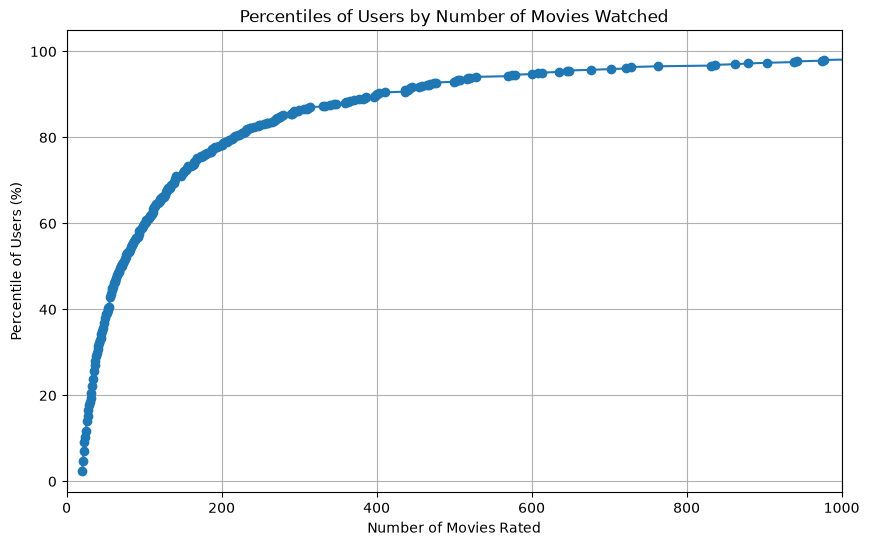

In [185]:
percentiles = movies_per_user.value_counts().sort_index().cumsum() / len(movies_per_user) * 100

# Plotting the percentiles
plt.figure(figsize=(10, 6))
plt.plot(percentiles.index, percentiles.values, marker='o')
plt.xlabel('Number of Movies Rated')
plt.ylabel('Percentile of Users (%)')
plt.title('Percentiles of Users by Number of Movies Watched')
plt.grid(True)
plt.xlim(0, 1000)
plt.show()

In [186]:
ratings_df.groupby(['userId','movieId']).size().max()

1

In [187]:
all_users_movie_combinations = pd.MultiIndex.from_product([ratings_df['userId'].unique(), movies_df['movieId'].unique()], names=['userId', 'movieId']).to_frame(index=False)

In [188]:
all_users_movie_combinations.head()

,userId,movieId
0,1,1
1,1,2
2,1,3
3,1,4
4,1,5


In [189]:
extended_ratings_df = pd.merge(all_users_movie_combinations, ratings_df, on=['userId', 'movieId'], how='left')
extended_ratings_df.fillna(0, inplace=True)

/var/folders/qm/jjr6jgjd4mg5n8mdb1n59gcw0000gn/T/ipykernel_54492/3467106652.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  extended_ratings_df.fillna(0, inplace=True)


## Combining DataFrames

In [190]:
merged_df = pd.merge(movies_df, extended_ratings_df, on='movieId', how='inner')

In [191]:
merged_df = merged_df.merge(users_df, on='userId')

In [192]:
ratings_df['rating'].value_counts()

rating
4.0    26818
3.0    20047
5.0    13211
3.5    13136
4.5     8551
2.0     7551
2.5     5550
1.0     2811
1.5     1791
0.5     1370
Name: count, dtype: int64

In [193]:
merged_df['watched'] = (merged_df['rating'] > 0) * 1

In [194]:
merged_df ['watched'].mean()

0.016968273253211548

In [195]:
merged_df

,movieId,title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,...,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length,watched
0,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,232,5.0,1.0,4.366379,0.0,0.000314,0.0,0.0,0.000000,1
1,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,29,5.0,2.0,3.948276,9.0,0.057426,17.0,3.0,10.333333,0
2,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,39,5.0,0.5,2.435897,0.0,0.040206,0.0,0.0,0.000000,0
3,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,216,5.0,1.0,3.555556,0.0,0.000003,0.0,0.0,0.000000,0
4,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,44,5.0,1.0,3.636364,0.0,0.074576,0.0,0.0,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5942615,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,1115,5.0,0.5,3.657399,7.0,0.000006,12.0,4.0,7.142857,0
5942616,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,187,5.0,1.0,3.786096,0.0,0.000005,0.0,0.0,0.000000,0
5942617,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,831,5.0,0.5,3.134176,0.0,0.000011,0.0,0.0,0.000000,0
5942618,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,37,4.0,3.0,3.270270,0.0,0.133094,0.0,0.0,0.000000,0


In [196]:
merged_df['watched'].mean()

0.016968273253211548

## Training a Binary Classification Model

In [197]:
merged_df

,movieId,title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,...,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length,watched
0,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,232,5.0,1.0,4.366379,0.0,0.000314,0.0,0.0,0.000000,1
1,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,29,5.0,2.0,3.948276,9.0,0.057426,17.0,3.0,10.333333,0
2,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,39,5.0,0.5,2.435897,0.0,0.040206,0.0,0.0,0.000000,0
3,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,216,5.0,1.0,3.555556,0.0,0.000003,0.0,0.0,0.000000,0
4,1,Toy Story (1995),1995.0,0,0,1,1,1,1,0,...,44,5.0,1.0,3.636364,0.0,0.074576,0.0,0.0,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5942615,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,1115,5.0,0.5,3.657399,7.0,0.000006,12.0,4.0,7.142857,0
5942616,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,187,5.0,1.0,3.786096,0.0,0.000005,0.0,0.0,0.000000,0
5942617,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,831,5.0,0.5,3.134176,0.0,0.000011,0.0,0.0,0.000000,0
5942618,193609,Andrew Dice Clay: Dice Rules (1991),1991.0,0,0,0,0,0,1,0,...,37,4.0,3.0,3.270270,0.0,0.133094,0.0,0.0,0.000000,0


In [198]:
merged_df_drop = merged_df.drop(columns=['rating', 'timestamp', 'title', 'movieId']).fillna(0)

In [199]:
train = merged_df_drop[merged_df_drop['userId'].isin(user_train['userId'])]
test = merged_df_drop[merged_df_drop['userId'].isin(user_test['userId'])]

In [200]:
positive_rows = train[train['watched'] == 1]
negative_rows = train[train['watched'] == 0]
sampled_negative_rows = negative_rows.groupby('userId', group_keys=False).sample(
    frac=0.05,
    random_state=42
)
reduced_train = pd.concat([positive_rows, sampled_negative_rows], ignore_index=True)
X_train = reduced_train.drop(columns=['watched'])
y_train = reduced_train['watched']
X_test = test.drop(columns = ['watched'])
y_test = test['watched']

In [201]:
X_train

,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,userId,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length
0,1995.0,0,0,1,1,1,1,0,0,0,...,1,232,5.0,1.0,4.366379,0.0,3.138685e-04,0.0,0.0,0.000000
1,1995.0,0,0,1,1,1,1,0,0,0,...,5,44,5.0,1.0,3.636364,0.0,7.457627e-02,0.0,0.0,0.000000
2,1995.0,0,0,1,1,1,1,0,0,0,...,15,135,5.0,1.0,3.448148,0.0,6.393456e-07,0.0,0.0,0.000000
3,1995.0,0,0,1,1,1,1,0,0,0,...,17,105,5.0,3.0,4.209524,0.0,4.941869e-06,0.0,0.0,0.000000
4,1995.0,0,0,1,1,1,1,0,0,0,...,18,502,5.0,0.5,3.732072,16.0,6.295688e-06,18.0,5.0,10.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307216,1987.0,0,0,0,0,0,1,0,0,0,...,610,1302,5.0,0.5,3.688556,3.0,7.930587e-05,16.0,6.0,12.666667
307217,1949.0,0,0,0,0,0,0,1,0,1,...,610,1302,5.0,0.5,3.688556,3.0,7.930587e-05,16.0,6.0,12.666667
307218,2011.0,0,0,0,0,0,1,0,0,1,...,610,1302,5.0,0.5,3.688556,3.0,7.930587e-05,16.0,6.0,12.666667
307219,2013.0,0,0,0,0,0,1,0,0,1,...,610,1302,5.0,0.5,3.688556,3.0,7.930587e-05,16.0,6.0,12.666667


In [202]:
%%time

log_reg = LogisticRegression(max_iter = 1000)    
log_reg.fit(X_train, y_train)

CPU times: user 4min 12s, sys: 1min 21s, total: 5min 34s
Wall time: 47.7 s


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [203]:
y_test_proba = log_reg.predict_proba(X_test)[:, 1]

In [204]:
y_test_proba[:10]

array([0.26402606, 0.30299966, 0.26825885, 0.16256472, 0.12316854,
       0.15808418, 0.26068797, 0.287056  , 0.15929435, 0.22692599])

In [205]:
test_results_df = merged_df.loc[test.index, ['userId', 'movieId']].copy()
test_results_df['watched'] = y_test.to_numpy()
test_results_df['probability'] = y_test_proba
test_results_df.head()

,userId,movieId,watched,probability
2,3,1,0,0.264026
6,7,1,1,0.303000
10,11,1,0,0.268259
11,12,1,0,0.162565
24,25,1,0,0.123169


In [206]:
user_id = test_results_df['userId'].iloc[0]
usr_tab = test_results_df[test_results_df['userId'] == user_id]

In [207]:
usr_tab.sort_values('probability', ascending=False).head(10)

,userId,movieId,watched,probability
4373702,3,71999,0,0.611773
5508912,3,140956,0,0.584258
4496922,3,79132,0,0.583221
2824912,3,6902,0,0.563472
5730342,3,164226,0,0.545296
3364762,3,26504,0,0.544688
2654112,3,6365,0,0.539583
2829792,3,6934,0,0.539583
3946702,3,52722,0,0.538931
4467642,3,77561,0,0.538442


In [208]:
usr_tab[usr_tab['watched'] == 1].sort_values('probability', ascending=False)

,userId,movieId,watched,probability
1686652,3,3703,1,0.421796
400162,3,849,1,0.419397
1306012,3,2851,1,0.351702
344652,3,688,1,0.324730
955872,3,2105,1,0.316597
4382852,3,72378,1,0.285426
2277742,3,5181,1,0.277108
947332,3,2090,1,0.267295
642942,3,1371,1,0.256488
332452,3,647,1,0.253529


## Evaluating Recommendations

In [209]:
user_ap_scores = test_results_df.groupby('userId').apply(
    lambda group: average_precision_score(group['watched'], group['probability'])
)
user_ap_scores.mean()

/var/folders/qm/jjr6jgjd4mg5n8mdb1n59gcw0000gn/T/ipykernel_54492/757062168.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  user_ap_scores = test_results_df.groupby('userId').apply(


0.045287116235431565